### Problem 9.1 : Applying QSVM on Iris Dataset

The iris dataset has 4 features and 3 classes, making it more complex than our previous binary classification example in Problem 9.

The ZZFeatureMap is configured to handle all 4 features of the iris dataset
We're using the same quantum kernel approach but with scaled data for better performance.

In [1]:
# !pip install matplotlib seaborn

In [2]:
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityQuantumKernel

from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
def load_and_prepare_data():
    """Load and preprocess the iris dataset."""
    # Load iris dataset
    iris = load_iris()
    X = iris.data
    y = iris.target
    feature_names = iris.feature_names
    
    # Scale the features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Split the data
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y, test_size=0.3, random_state=42
    )
    
    df = pd.DataFrame(iris.data, columns=feature_names)
    df["class"] = pd.Series(iris.target)
    print("Let us check the pairplot to visualise the correlation between the features")
    sns.pairplot(df, hue="class", palette="tab10")

    return X_train, X_test, y_train, y_test, feature_names

In [4]:
def create_quantum_kernel(feature_dimension=4):
    """Create a quantum kernel using the ZZ feature map."""
    # `zz_feature_map` replaces the deprecated `ZZFeatureMap` class (removed in Qiskit 3.0).
    feature_map = zz_feature_map(
        feature_dimension=feature_dimension,
        reps=2,
        entanglement='linear'
    )

    return FidelityQuantumKernel(
        feature_map=feature_map
    )


In [5]:
def train_and_evaluate_qsvm(X_train, X_test, y_train, y_test, quantum_kernel):
    """Train and evaluate the quantum SVM model."""
    # Compute kernel matrices
    print("Computing kernel matrices...")
    kernel_matrix_train = quantum_kernel.evaluate(X_train, X_train)
    kernel_matrix_test = quantum_kernel.evaluate(X_test, X_train)
    
    # Train SVM with quantum kernel
    print("Training SVM with quantum kernel...")
    svm = SVC(kernel='precomputed')
    svm.fit(kernel_matrix_train, y_train)
    
    # Make predictions
    y_pred = svm.predict(kernel_matrix_test)
    
    return y_pred

In [6]:
def plot_confusion_matrix(y_test, y_pred):
    """Plot confusion matrix using seaborn."""
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

Loading and preparing data...
Let us check the pairplot to visualise the correlation between the features


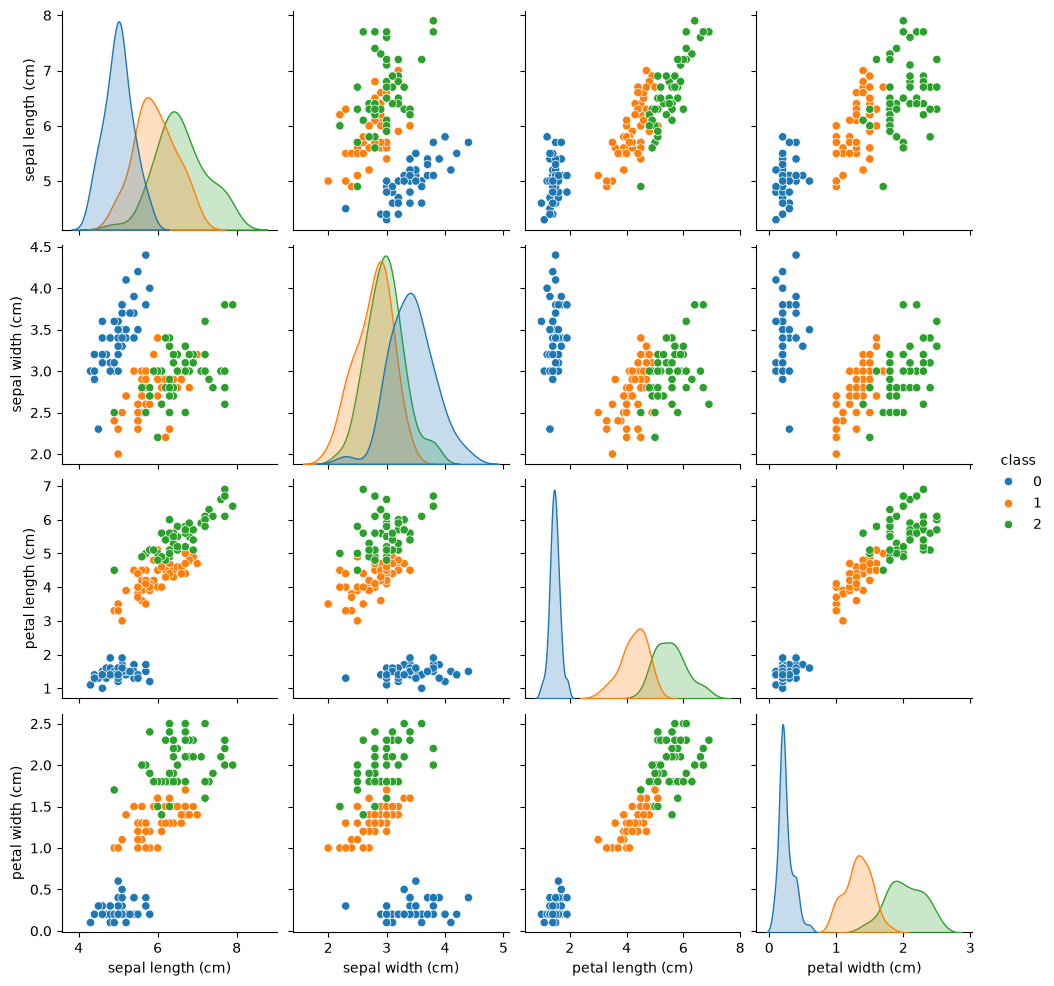

In [7]:
# Step 1: Load and prepare data
print("Loading and preparing data...")
X_train, X_test, y_train, y_test, feature_names = load_and_prepare_data()

In [8]:
# Print dataset information
print("\nDataset Information:")
print(f"Training set size: {X_train.shape}")
print(f"Test set size: {X_test.shape}")
print(f"Features: {feature_names}")


Dataset Information:
Training set size: (105, 4)
Test set size: (45, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [9]:
# Step 2: Create quantum kernel
print("\nCreating quantum kernel...")
quantum_kernel = create_quantum_kernel(feature_dimension=4)  # iris has 4 features


Creating quantum kernel...


In [10]:
# Step 3: Train and evaluate model
print("\nTraining and evaluating model...")
y_pred = train_and_evaluate_qsvm(
    X_train, X_test, y_train, y_test, quantum_kernel
)


Training and evaluating model...
Computing kernel matrices...


Training SVM with quantum kernel...


In [11]:
# Step 4: Display results
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['setosa', 'versicolor', 'virginica']))


Classification Report:
              precision    recall  f1-score   support

      setosa       0.90      0.47      0.62        19
  versicolor       0.30      0.46      0.36        13
   virginica       0.47      0.54      0.50        13

    accuracy                           0.49        45
   macro avg       0.56      0.49      0.49        45
weighted avg       0.60      0.49      0.51        45




Plotting confusion matrix...


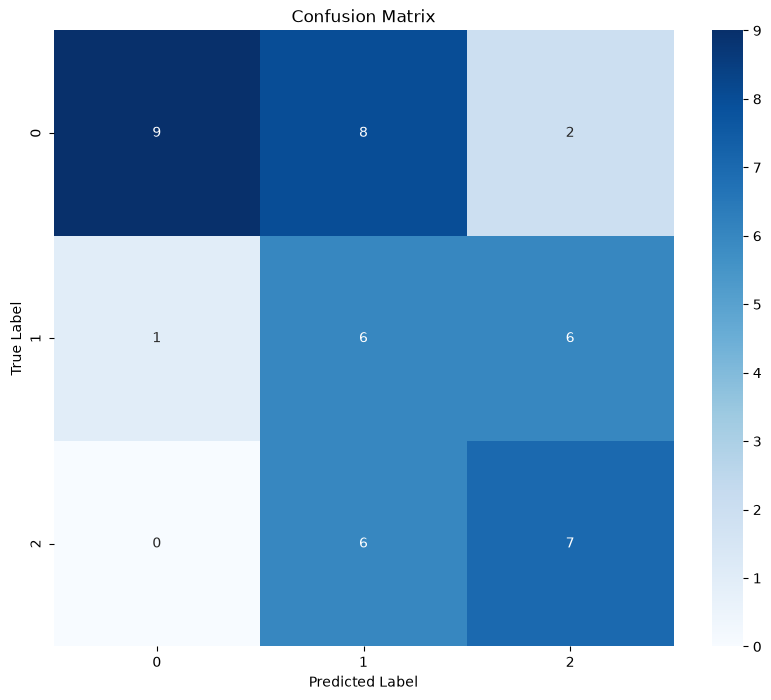

In [12]:
# Step 5: Plot confusion matrix
print("\nPlotting confusion matrix...")
plot_confusion_matrix(y_test, y_pred)